In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/raw/household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
import os

print(os.getcwd())

C:\Users\ashig\OneDrive\Desktop\ML project\01_data_exploration.ipynb


In [6]:
import os

print(os.listdir())


['.ipynb_checkpoints', '01_data_exploration.ipynb', 'models']


In [7]:
df = pd.read_csv(
    "../data/raw/household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/raw/household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [9]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (2075259, 9)

Column names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


In [10]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True
)

df = df.drop(columns=["Date", "Time"])
df = df.set_index("Datetime")

df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [11]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.dtypes)

Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


In [12]:
print(df.isnull().sum())

Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [13]:

df = df.interpolate(method="time", limit_direction="both")

print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [14]:
hourly_energy = (
    df["Global_active_power"].resample("h").sum() / 60
)

hourly_energy = hourly_energy.to_frame(name="Energy_kWh")

print(hourly_energy.head())
print("Shape:", hourly_energy.shape)

                     Energy_kWh
Datetime                       
2006-12-16 17:00:00    2.533733
2006-12-16 18:00:00    3.632200
2006-12-16 19:00:00    3.400233
2006-12-16 20:00:00    3.268567
2006-12-16 21:00:00    3.056467
Shape: (34589, 1)


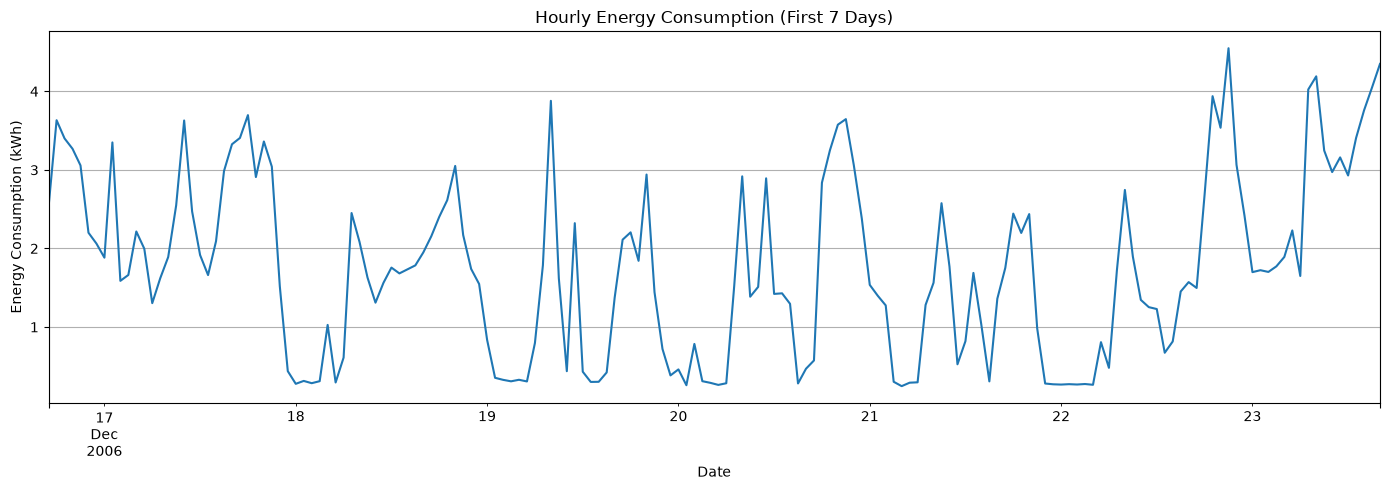

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

hourly_energy.iloc[:168]["Energy_kWh"].plot()

plt.title("Hourly Energy Consumption (First 7 Days)")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
hourly_energy.describe()

,Energy_kWh
count,34589.000000
mean,1.090237
std,0.894216
min,0.046733
25%,0.342867
50%,0.803216
75%,1.578700
max,6.560533


<Figure size 1400x500 with 0 Axes>

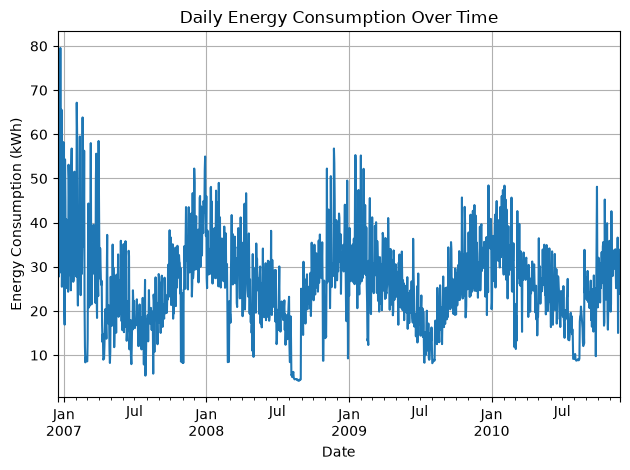

In [17]:
daily_energy = hourly_energy.resample("D").sum()

plt.figure(figsize=(14, 5))
daily_energy.plot(legend=False)

plt.title("Daily Energy Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.grid(True)
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

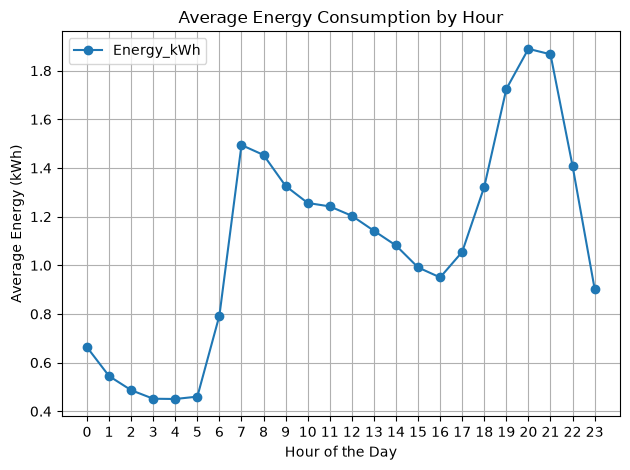

In [18]:
hourly_pattern = hourly_energy.groupby(
    hourly_energy.index.hour
).mean()

plt.figure(figsize=(12, 5))
hourly_pattern.plot(marker="o")

plt.title("Average Energy Consumption by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Energy (kWh)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
model_df = hourly_energy.copy()

model_df["hour"] = model_df.index.hour
model_df["day_of_week"] = model_df.index.dayofweek
model_df["month"] = model_df.index.month
model_df["is_weekend"] = (
    model_df.index.dayofweek >= 5
).astype(int)

# Previous consumption
model_df["lag_1"] = model_df["Energy_kWh"].shift(1)
model_df["lag_24"] = model_df["Energy_kWh"].shift(24)
model_df["lag_168"] = model_df["Energy_kWh"].shift(168)

# Past rolling averages (exclude current hour)
model_df["rolling_mean_24"] = (
    model_df["Energy_kWh"].shift(1).rolling(24).mean()
)

model_df["rolling_mean_168"] = (
    model_df["Energy_kWh"].shift(1).rolling(168).mean()
)

# Remove rows without sufficient historical data
model_df = model_df.dropna()

model_df.head()

,Energy_kWh,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168
Datetime,,,,,,,,,,
2006-12-23 17:00:00,5.452533,17,5,12,1,4.349100,1.496800,2.533733,2.934890,1.753834
2006-12-23 18:00:00,3.879400,18,5,12,1,5.452533,2.686967,3.632200,3.099713,1.771207
2006-12-23 19:00:00,4.117833,19,5,12,1,3.879400,3.938167,3.400233,3.149397,1.772679
2006-12-23 20:00:00,4.181400,20,5,12,1,4.117833,3.536067,3.268567,3.156883,1.776950
2006-12-23 21:00:00,3.288433,21,5,12,1,4.181400,4.548667,3.056467,3.183772,1.782384


In [20]:
split_index = int(len(model_df) * 0.8)

train = model_df.iloc[:split_index]
test = model_df.iloc[split_index:]

X_train = train.drop(columns=["Energy_kWh"])
y_train = train["Energy_kWh"]

X_test = test.drop(columns=["Energy_kWh"])
y_test = test["Energy_kWh"]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training samples: 27536
Testing samples: 6885
Training period: 2006-12-23 17:00:00 to 2010-02-13 00:00:00
Testing period: 2010-02-13 01:00:00 to 2010-11-26 21:00:00


In [21]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [22]:
y_pred = rf_model.predict(X_test)

print("Actual values:", y_test.values[:5])
print("Predicted values:", y_pred[:5])

Actual values: [0.3305     0.28696667 0.29213333 0.3372     0.35716667]
Predicted values: [0.3577607  0.35485782 0.33905727 0.36644518 0.36780021]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

wape = (
    np.sum(np.abs(y_test.values - y_pred))
    / np.sum(np.abs(y_test.values))
) * 100

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("WAPE:", round(wape, 2), "%")


MAE: 0.3314
RMSE: 0.4817
WAPE: 33.07 %


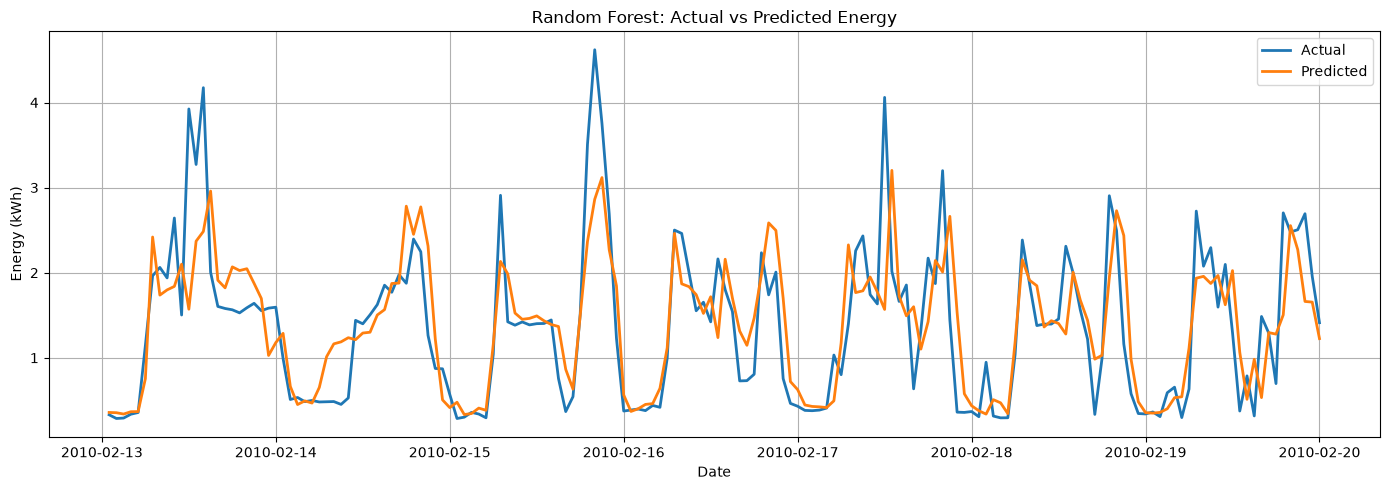

In [24]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index[:168],
    y_test.values[:168],
    label="Actual",
    linewidth=2
)

plt.plot(
    y_test.index[:168],
    y_pred[:168],
    label="Predicted",
    linewidth=2
)

plt.title("Random Forest: Actual vs Predicted Energy")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)
print("R2 Score (%):", r2 * 100)

R2 Score: 0.5623303531016665
R2 Score (%): 56.23303531016665


In [26]:
# Keep only the target column
df = df[["Global_active_power"]].copy()

# Ensure numeric data
df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"], errors="coerce"
)

# Filter invalid values
df = df.dropna(subset=["Global_active_power"])
df = df[df["Global_active_power"] >= 0]

print("Filtered shape:", df.shape)
print(df.head())

Filtered shape: (2075259, 1)
                     Global_active_power
Datetime                                
2006-12-16 17:24:00                4.216
2006-12-16 17:25:00                5.360
2006-12-16 17:26:00                5.374
2006-12-16 17:27:00                5.388
2006-12-16 17:28:00                3.666


In [27]:
hourly_energy = (
    df["Global_active_power"]
    .resample("h")
    .mean()
    .to_frame(name="Energy_kWh")
)

print(hourly_energy.head())
print("Hourly shape:", hourly_energy.shape)

                     Energy_kWh
Datetime                       
2006-12-16 17:00:00    4.222889
2006-12-16 18:00:00    3.632200
2006-12-16 19:00:00    3.400233
2006-12-16 20:00:00    3.268567
2006-12-16 21:00:00    3.056467
Hourly shape: (34589, 1)


In [28]:
model_df = hourly_energy.copy()

model_df["hour"] = model_df.index.hour
model_df["day_of_week"] = model_df.index.dayofweek
model_df["month"] = model_df.index.month
model_df["is_weekend"] = (
    model_df.index.dayofweek >= 5
).astype(int)

model_df["lag_1"] = model_df["Energy_kWh"].shift(1)
model_df["lag_24"] = model_df["Energy_kWh"].shift(24)
model_df["lag_168"] = model_df["Energy_kWh"].shift(168)

model_df["rolling_mean_24"] = (
    model_df["Energy_kWh"].shift(1).rolling(24).mean()
)

model_df["rolling_mean_168"] = (
    model_df["Energy_kWh"].shift(1).rolling(168).mean()
)

model_df = model_df.dropna()

split_index = int(len(model_df) * 0.8)

train = model_df.iloc[:split_index]
test = model_df.iloc[split_index:]

X_train = train.drop(columns=["Energy_kWh"])
y_train = train["Energy_kWh"]

X_test = test.drop(columns=["Energy_kWh"])
y_test = test["Energy_kWh"]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (27536, 9)
Testing: (6885, 9)


In [29]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [30]:
y_pred = rf_model.predict(X_test)

In [31]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)
print("R2 Score (%):", r2 * 100)

R2 Score: 0.5628164163997587
R2 Score (%): 56.28164163997587


In [32]:
import numpy as np
import pandas as pd

model_df = hourly_energy.copy()

# Cyclical time features
model_df["hour_sin"] = np.sin(2 * np.pi * model_df.index.hour / 24)
model_df["hour_cos"] = np.cos(2 * np.pi * model_df.index.hour / 24)

model_df["dow_sin"] = np.sin(2 * np.pi * model_df.index.dayofweek / 7)
model_df["dow_cos"] = np.cos(2 * np.pi * model_df.index.dayofweek / 7)

model_df["month_sin"] = np.sin(2 * np.pi * model_df.index.month / 12)
model_df["month_cos"] = np.cos(2 * np.pi * model_df.index.month / 12)

model_df["is_weekend"] = (model_df.index.dayofweek >= 5).astype(int)

# Historical consumption
for lag in [1, 2, 3, 6, 12, 24, 48, 72, 168]:
    model_df[f"lag_{lag}"] = model_df["Energy_kWh"].shift(lag)

# Rolling statistics, using past observations only
for window in [6, 12, 24, 48, 168]:
    past = model_df["Energy_kWh"].shift(1)
    model_df[f"rolling_mean_{window}"] = past.rolling(window).mean()
    model_df[f"rolling_std_{window}"] = past.rolling(window).std()

model_df = model_df.dropna()

# Chronological 80/20 split
split_index = int(len(model_df) * 0.8)

train = model_df.iloc[:split_index]
test = model_df.iloc[split_index:]

X_train = train.drop(columns=["Energy_kWh"])
y_train = train["Energy_kWh"]

X_test = test.drop(columns=["Energy_kWh"])
y_test = test["Energy_kWh"]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (27536, 26)
Testing: (6885, 26)


In [33]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=700,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost training completed!")

XGBoost training completed!


In [34]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=700,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost training completed!")

XGBoost training completed!


In [35]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

r2 = r2_score(y_test, y_pred_xgb)
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("XGBoost R2:", round(r2, 4))
print("XGBoost R2 (%):", round(r2 * 100, 2))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

XGBoost R2: 0.5909
XGBoost R2 (%): 59.09
MAE: 0.3199
RMSE: 0.4657


In [36]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=700,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost training completed!")

XGBoost training completed!


In [37]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

r2 = r2_score(y_test, y_pred_xgb)
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("XGBoost R2:", round(r2, 4))
print("XGBoost R2 (%):", round(r2 * 100, 2))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

XGBoost R2: 0.5909
XGBoost R2 (%): 59.09
MAE: 0.3199
RMSE: 0.4657


In [38]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (27536, 26)
X_test: (6885, 26)
y_train: (27536,)
y_test: (6885,)


In [39]:
split_index = int(len(hourly_energy) * 0.8)

train = hourly_energy.iloc[:split_index]
test = hourly_energy.iloc[split_index:]

X_train = train.drop(columns=["Energy_kWh"])
y_train = train["Energy_kWh"]

X_test = test.drop(columns=["Energy_kWh"])
y_test = test["Energy_kWh"]

In [40]:
hourly_energy = (
    df["Global_active_power"]
    .resample("h")
    .mean()
    .to_frame(name="Energy_kWh")
)

print(hourly_energy.shape)
hourly_energy.head()


(34589, 1)


,Energy_kWh
Datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467


In [41]:
split_index = int(len(hourly_energy) * 0.8)

train = hourly_energy.iloc[:split_index]
test = hourly_energy.iloc[split_index:]

X_train = train.drop(columns=["Energy_kWh"])
y_train = train["Energy_kWh"]

X_test = test.drop(columns=["Energy_kWh"])
y_test = test["Energy_kWh"]

print(X_train.shape)
print(X_test.shape)

(27671, 0)
(6918, 0)


In [42]:
features = hourly_energy.copy()

# Time-based features
features["hour"] = features.index.hour
features["day_of_week"] = features.index.dayofweek
features["month"] = features.index.month
features["is_weekend"] = (features["day_of_week"] >= 5).astype(int)

# Cyclical features
features["hour_sin"] = np.sin(2 * np.pi * features["hour"] / 24)
features["hour_cos"] = np.cos(2 * np.pi * features["hour"] / 24)

features["day_sin"] = np.sin(2 * np.pi * features["day_of_week"] / 7)
features["day_cos"] = np.cos(2 * np.pi * features["day_of_week"] / 7)

features["month_sin"] = np.sin(2 * np.pi * features["month"] / 12)
features["month_cos"] = np.cos(2 * np.pi * features["month"] / 12)

# Lag features
for lag in [1, 2, 3, 6, 12, 24, 48, 72, 168]:
    features[f"lag_{lag}"] = features["Energy_kWh"].shift(lag)

# Rolling features
for window in [6, 12, 24, 48, 168]:
    shifted = features["Energy_kWh"].shift(1)
    features[f"rolling_mean_{window}"] = shifted.rolling(window).mean()
    features[f"rolling_std_{window}"] = shifted.rolling(window).std()

features = features.dropna()

print("Feature engineering completed!")
print(features.shape)

Feature engineering completed!
(34421, 30)


In [43]:
split_index = int(len(features) * 0.8)

train = features.iloc[:split_index]
test = features.iloc[split_index:]

X_train = train.drop(columns=["Energy_kWh"])
y_train = train["Energy_kWh"]

X_test = test.drop(columns=["Energy_kWh"])
y_test = test["Energy_kWh"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (27536, 29)
X_test: (6885, 29)
y_train: (27536,)
y_test: (6885,)


In [44]:
print("Hourly data:", len(hourly_energy))
print("Start date:", hourly_energy.index.min())
print("End date:", hourly_energy.index.max())
print("Original data:", df.shape)

Hourly data: 34589
Start date: 2006-12-16 17:00:00
End date: 2010-11-26 21:00:00
Original data: (2075259, 1)


In [45]:
print("Hourly data shape:", hourly_energy.shape)

print("\nMissing values:")
print(hourly_energy.isna().sum())

print("\nNon-missing values:")
print(hourly_energy.notna().sum())

print("\nData summary:")
print(hourly_energy["Energy_kWh"].describe())

Hourly data shape: (34589, 1)

Missing values:
Energy_kWh    0
dtype: int64

Non-missing values:
Energy_kWh    34589
dtype: int64

Data summary:
count    34589.000000
mean         1.090311
std          0.894323
min          0.124000
25%          0.342867
50%          0.803267
75%          1.578700
max          6.560533
Name: Energy_kWh, dtype: float64


In [46]:
print("Features before dropping NaN:", len(hourly_energy))
print("Features after dropping NaN:", len(features))
print("\nMissing values in features:")
print(features.isna().sum().sort_values(ascending=False).head(10))

Features before dropping NaN: 34589
Features after dropping NaN: 34421

Missing values in features:
Energy_kWh     0
hour           0
day_of_week    0
month          0
is_weekend     0
hour_sin       0
hour_cos       0
day_sin        0
day_cos        0
month_sin      0
dtype: int64


In [47]:
from xgboost import XGBRegressor

print("XGBoost is ready!")

XGBoost is ready!


In [48]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2,
    tree_method="hist"
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [49]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

y_pred_xgb = xgb_model.predict(X_test)

r2 = r2_score(y_test, y_pred_xgb)
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("XGBoost R2:", round(r2, 4))
print("XGBoost R2 (%):", round(r2 * 100, 2))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

XGBoost R2: 0.5819
XGBoost R2 (%): 58.19
MAE: 0.327
RMSE: 0.4708


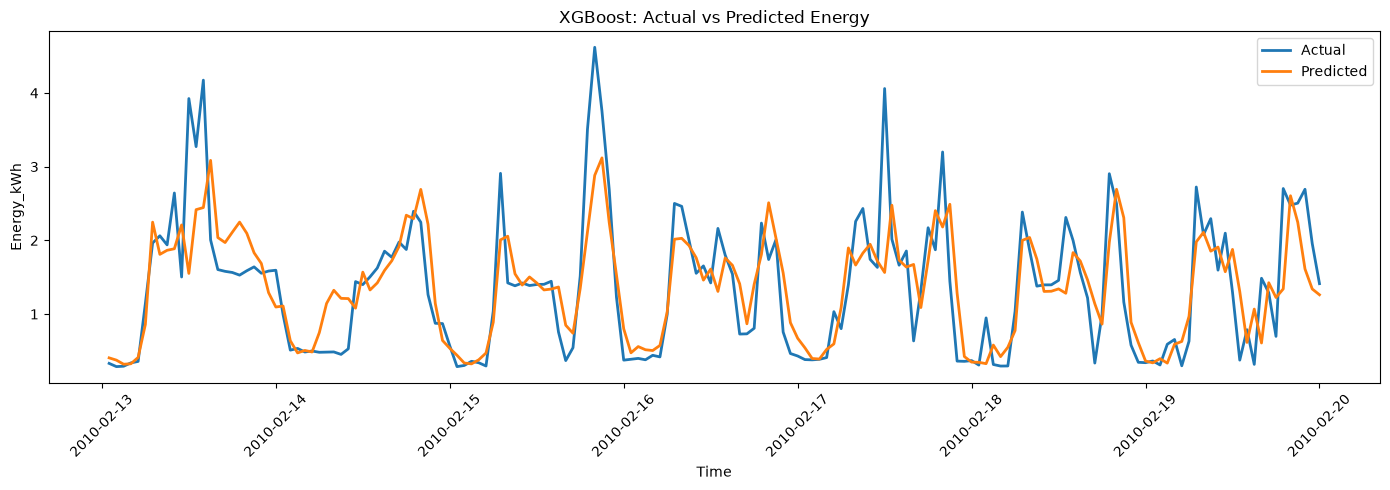

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index[:168],
    y_test.iloc[:168],
    label="Actual",
    linewidth=2
)

plt.plot(
    y_test.index[:168],
    y_pred_xgb[:168],
    label="Predicted",
    linewidth=2
)

plt.title("XGBoost: Actual vs Predicted Energy")
plt.xlabel("Time")
plt.ylabel("Energy_kWh")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

y_pred_baseline = X_test["lag_1"]

print("Baseline R2:", round(r2_score(y_test, y_pred_baseline), 4))
print("Baseline MAE:", round(mean_absolute_error(y_test, y_pred_baseline), 4))
print("XGBoost R2:", round(r2_score(y_test, y_pred_xgb), 4))
print("XGBoost MAE:", round(mean_absolute_error(y_test, y_pred_xgb), 4))

Baseline R2: 0.3447
Baseline MAE: 0.3808
XGBoost R2: 0.5819
XGBoost MAE: 0.327


In [52]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(15))

lag_1               0.273787
lag_168             0.137184
lag_24              0.087367
rolling_mean_48     0.048754
rolling_mean_6      0.046551
lag_2               0.040411
lag_72              0.038864
hour_cos            0.037482
hour                0.034063
rolling_mean_12     0.030682
hour_sin            0.029587
lag_48              0.027314
rolling_std_48      0.020687
lag_12              0.016498
rolling_mean_168    0.013914
dtype: float32


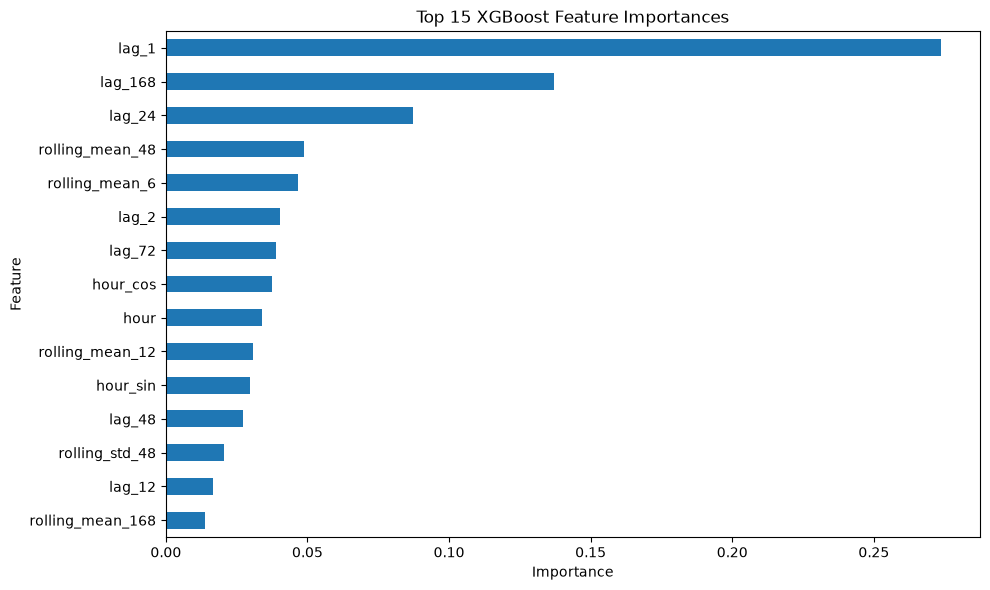

In [53]:
plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [54]:
print(type(xgb_model))

<class 'xgboost.sklearn.XGBRegressor'>


In [55]:
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2,
    tree_method="hist"
)

model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [56]:
from xgboost import XGBRegressor

In [57]:
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

In [58]:
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2,
    tree_method="hist"
)

model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [59]:
for name, value in globals().copy().items():
    if any(word in name.lower() for word in ["df", "hour", "model", "train", "feature"]):
        print(name, type(value))

model <class 'xgboost.sklearn.XGBRegressor'>
df <class 'pandas.DataFrame'>
hourly_energy <class 'pandas.DataFrame'>
hourly_pattern <class 'pandas.DataFrame'>
model_df <class 'pandas.DataFrame'>
train <class 'pandas.DataFrame'>
X_train <class 'pandas.DataFrame'>
y_train <class 'pandas.Series'>
rf_model <class 'sklearn.ensemble._forest.RandomForestRegressor'>
xgb_model <class 'xgboost.sklearn.XGBRegressor'>
features <class 'pandas.DataFrame'>


In [60]:
print("Model dataset:", model_df.shape)
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())

print("Model columns:", model_df.columns.tolist())

Model dataset: (34421, 27)
Training features: (27536, 29)
Training target: (27536,)
X_test exists: True
y_test exists: True
Model columns: ['Energy_kWh', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_24', 'lag_48', 'lag_72', 'lag_168', 'rolling_mean_6', 'rolling_std_6', 'rolling_mean_12', 'rolling_std_12', 'rolling_mean_24', 'rolling_std_24', 'rolling_mean_48', 'rolling_std_48', 'rolling_mean_168', 'rolling_std_168']


In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = xgb_model.predict(X_test)

print("R² Score:", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))

R² Score: 0.5819
MAE: 0.327
RMSE: 0.4708


In [62]:
import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "xgb_model.joblib"

joblib.dump(xgb_model, model_path)

print("Model saved successfully:", model_path.resolve())

Model saved successfully: C:\Users\ashig\OneDrive\Desktop\ML project\01_data_exploration.ipynb\models\xgb_model.joblib


In [63]:
loaded_model = joblib.load(model_path)

print(np.allclose(
    xgb_model.predict(X_test),
    loaded_model.predict(X_test)
))

True


In [64]:
import joblib
import json
from pathlib import Path

project_dir = Path(
    r"C:\Users\ashig\OneDrive\Desktop\ML project"
)

model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model in the main project
joblib.dump(xgb_model, model_dir / "xgb_model.joblib")

# Save the exact feature names and their order
with open(model_dir / "feature_names.json", "w") as f:
    json.dump(list(X_train.columns), f, indent=4)

print("Model and feature names saved successfully!")
print("Model location:", model_dir / "xgb_model.joblib")
print("Number of features:", len(X_train.columns))

Model and feature names saved successfully!
Model location: C:\Users\ashig\OneDrive\Desktop\ML project\models\xgb_model.joblib
Number of features: 29


In [65]:
import json
from pathlib import Path

project_dir = Path(
    r"C:\Users\ashig\OneDrive\Desktop\ML project"
)

model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

feature_names = list(X_train.columns)

with open(model_dir / "feature_names.json", "w") as f:
    json.dump(feature_names, f, indent=4)

print("Feature names saved successfully!")
print("Number of features:", len(feature_names))

Feature names saved successfully!
Number of features: 29


In [66]:
import joblib

model_path = r"C:\Users\ashig\OneDrive\Desktop\ML project\models\xgb_model.joblib"

saved_model = joblib.load(model_path)

feature_names = saved_model.get_booster().feature_names

print(feature_names)

['hour', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_24', 'lag_48', 'lag_72', 'lag_168', 'rolling_mean_6', 'rolling_std_6', 'rolling_mean_12', 'rolling_std_12', 'rolling_mean_24', 'rolling_std_24', 'rolling_mean_48', 'rolling_std_48', 'rolling_mean_168', 'rolling_std_168']


In [67]:
import json
from pathlib import Path

if feature_names is not None:
    feature_path = Path(
        r"C:\Users\ashig\OneDrive\Desktop\ML project\models\feature_names.json"
    )

    with open(feature_path, "w") as f:
        json.dump(feature_names, f, indent=4)

    print("Feature names saved:", len(feature_names))
else:
    print("Feature names are not stored in the model.")


Feature names saved: 29


In [68]:

import json
from pathlib import Path

feature_path = Path(
    r"C:\Users\ashig\OneDrive\Desktop\ML project\models\feature_names.json"
)

with open(feature_path, "w") as f:
    json.dump(feature_names, f, indent=4)

print("Feature names saved successfully!")
print("Total features:", len(feature_names))
print("File:", feature_path)


Feature names saved successfully!
Total features: 29
File: C:\Users\ashig\OneDrive\Desktop\ML project\models\feature_names.json


In [69]:
print(hourly_energy.columns.tolist())
print(hourly_energy.index[:5])


['Energy_kWh']
DatetimeIndex(['2006-12-16 17:00:00', '2006-12-16 18:00:00',
               '2006-12-16 19:00:00', '2006-12-16 20:00:00',
               '2006-12-16 21:00:00'],
              dtype='datetime64[us]', name='Datetime', freq='h')


In [70]:
import pandas as pd
from pathlib import Path

file_path = Path(
    r"C:\Users\ashig\OneDrive\Desktop\ML project\data\raw\household_power_consumption.txt"
)

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"],
    errors="coerce"
)

df = df.dropna(subset=["datetime"])
df = df.set_index("datetime").sort_index()

hourly_energy = (
    df["Global_active_power"]
    .resample("h")
    .mean()
    .to_frame(name="Energy_kWh")
)

print("Dataset loaded!")
print(hourly_energy.shape)
print(hourly_energy.head())

Dataset loaded!
(34589, 1)
                     Energy_kWh
datetime                       
2006-12-16 17:00:00    4.222889
2006-12-16 18:00:00    3.632200
2006-12-16 19:00:00    3.400233
2006-12-16 20:00:00    3.268567
2006-12-16 21:00:00    3.056467


In [71]:
print(hourly_energy.columns.tolist())
print(hourly_energy.index[:5])
print(hourly_energy.isna().sum())

['Energy_kWh']
DatetimeIndex(['2006-12-16 17:00:00', '2006-12-16 18:00:00',
               '2006-12-16 19:00:00', '2006-12-16 20:00:00',
               '2006-12-16 21:00:00'],
              dtype='datetime64[us]', name='datetime', freq='h')
Energy_kWh    421
dtype: int64


In [72]:

import pandas as pd
import json
import urllib.request

# Get the hourly target series
series = hourly_energy["Energy_kWh"].dropna().sort_index()

# Find continuous runs of hourly observations
runs = []
current_run = []

for timestamp, value in series.items():
    if current_run and timestamp - current_run[-1][0] != pd.Timedelta(hours=1):
        runs.append(current_run)
        current_run = []
    current_run.append((timestamp, float(value)))

if current_run:
    runs.append(current_run)

# Select a continuous run with at least 168 readings
valid_runs = [run for run in runs if len(run) >= 168]

if not valid_runs:
    raise ValueError("No 168 consecutive hourly readings found.")

history = valid_runs[-1][-168:]

print("Number of observations:", len(history))
print("First timestamp:", history[0][0])
print("Last timestamp:", history[-1][0])


Number of observations: 168
First timestamp: 2010-11-19 22:00:00
Last timestamp: 2010-11-26 21:00:00


In [73]:

payload = {
    "observations": [
        {
            "timestamp": timestamp.isoformat(),
            "value": value
        }
        for timestamp, value in history
    ]
}

data = json.dumps(payload).encode("utf-8")

request = urllib.request.Request(
    "http://127.0.0.1:8000/predict",
    data=data,
    headers={"Content-Type": "application/json"},
    method="POST"
)

with urllib.request.urlopen(request) as response:
    result = json.loads(response.read().decode("utf-8"))

print(json.dumps(result, indent=4))


{
    "prediction_timestamp": "2010-11-26T22:00:00",
    "predicted_energy_value": 0.7877999544143677,
    "unit": "same unit as the training target"
}


In [74]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions for the unseen test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("XGBoost Model Evaluation")
print(f"MAE:  {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"R²:   {r2:.4f}")


XGBoost Model Evaluation
MAE:  0.3270 kW
RMSE: 0.4708 kW
R²:   0.5819


In [75]:


import joblib

model = joblib.load("../models/xgb_model.joblib")

print("XGBoost model loaded successfully!")


XGBoost model loaded successfully!


In [76]:

print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())


X_test exists: True
y_test exists: True


In [77]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions for the unseen test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("XGBoost Model Evaluation")
print(f"MAE:  {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"R²:   {r2:.4f}")


XGBoost Model Evaluation
MAE:  0.3270 kW
RMSE: 0.4708 kW
R²:   0.5819


In [78]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline: use the previous hour's value
baseline_pred = X_test["lag_1"].to_numpy()

print("Baseline MAE:",
      mean_absolute_error(y_test, baseline_pred))
print("Baseline RMSE:",
      np.sqrt(mean_squared_error(y_test, baseline_pred)))
print("Baseline R²:",
      r2_score(y_test, baseline_pred))


Baseline MAE: 0.38080256770337406
Baseline RMSE: 0.5893821337619741
Baseline R²: 0.34473410096428336


In [79]:

from pathlib import Path
from datetime import timedelta
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Locate project files
BASE_DIR = Path.cwd()
if not (BASE_DIR / "data" / "raw" / "household_power_consumption.txt").exists():
    BASE_DIR = BASE_DIR.parent

DATA_PATH = BASE_DIR / "data" / "raw" / "household_power_consumption.txt"
MODEL_PATH = BASE_DIR / "models" / "xgb_model.joblib"
FEATURE_PATH = BASE_DIR / "models" / "feature_names.json"

# Load model and feature order
model = joblib.load(MODEL_PATH)
with open(FEATURE_PATH, "r") as f:
    feature_names = json.load(f)

# Load the historical dataset
df = pd.read_csv(
    DATA_PATH,
    sep=";",
    usecols=["Date", "Time", "Global_active_power"],
    na_values=["?"],
    low_memory=False
)

df["timestamp"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)
df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"], errors="coerce"
)
df = df.dropna(subset=["timestamp", "Global_active_power"])

# Same hourly mean aggregation used in the API
hourly = (
    df.set_index("timestamp")["Global_active_power"]
    .resample("h").mean().dropna()
)

# Keep the latest continuous hourly section
run_ids = hourly.index.to_series().diff().ne(
    pd.Timedelta(hours=1)
).cumsum()

valid_runs = [run for _, run in hourly.groupby(run_ids) if len(run) >= 168]
if not valid_runs:
    raise ValueError("No continuous hourly segment of at least 168 hours.")

series = valid_runs[-1]

print("Backtesting data:", series.index[0], "to", series.index[-1])
print("Hourly observations:", len(series))

# Chronological 80/20 split
split_index = int(len(series) * 0.8)
test_start = split_index

def make_features(history, prediction_time):
    values = np.asarray(history, dtype=float)
    hour = prediction_time.hour
    day = prediction_time.weekday()
    month = prediction_time.month

    features = {
        "hour": hour,
        "day_of_week": day,
        "month": month,
        "is_weekend": int(day >= 5),
        "hour_sin": np.sin(2 * np.pi * hour / 24),
        "hour_cos": np.cos(2 * np.pi * hour / 24),
        "day_sin": np.sin(2 * np.pi * day / 7),
        "day_cos": np.cos(2 * np.pi * day / 7),
        "month_sin": np.sin(2 * np.pi * month / 12),
        "month_cos": np.cos(2 * np.pi * month / 12),
    }

    for lag in [1, 2, 3, 6, 12, 24, 48, 72, 168]:
        features[f"lag_{lag}"] = float(values[-lag])

    for window in [6, 12, 24, 48, 168]:
        recent = values[-window:]
        features[f"rolling_mean_{window}"] = float(np.mean(recent))
        features[f"rolling_std_{window}"] = float(np.std(recent, ddof=1))

    return pd.DataFrame(
        [[features[name] for name in feature_names]],
        columns=feature_names
    )

# Recursive backtesting
horizons = [24, 48, 72, 168]
results = []

# Move the forecast origin forward by 24 hours each time
for horizon in horizons:
    actual_all = []
    predicted_all = []

    for origin in range(test_start, len(series) - horizon + 1, 24):
        # Only observations before the forecast origin are known
        history = list(series.iloc[origin - 168:origin].values)
        forecast_time = series.index[origin]

        predictions = []

        for step in range(horizon):
            current_time = forecast_time + timedelta(hours=step)
            X_input = make_features(history, current_time)
            prediction = float(model.predict(X_input)[0])

            predictions.append(prediction)
            history.append(prediction)

        actual = series.iloc[origin:origin + horizon].values

        actual_all.extend(actual)
        predicted_all.extend(predictions)

    actual_all = np.asarray(actual_all)
    predicted_all = np.asarray(predicted_all)

    results.append({
        "Horizon (hours)": horizon,
        "MAE (kW)": mean_absolute_error(actual_all, predicted_all),
        "RMSE (kW)": np.sqrt(mean_squared_error(actual_all, predicted_all)),
        "R²": r2_score(actual_all, predicted_all),
        "Forecast points": len(actual_all)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))


Backtesting data: 2010-09-28 19:00:00 to 2010-11-26 21:00:00
Hourly observations: 1419
 Horizon (hours)  MAE (kW)  RMSE (kW)     R²  Forecast points
              24    0.4387     0.6098 0.4431              264
              48    0.4424     0.6102 0.4438              480
              72    0.4486     0.6213 0.4310              648
             168    0.4785     0.6661 0.3680              840


In [80]:

baseline_results = []

for horizon in [24, 48, 72, 168]:
    actual_all = []
    baseline_all = []

    for origin in range(test_start, len(series) - horizon + 1, 24):
        # Persistence baseline repeats the latest known value
        last_value = float(series.iloc[origin - 1])
        baseline_predictions = [last_value] * horizon

        actual = series.iloc[origin:origin + horizon].values

        actual_all.extend(actual)
        baseline_all.extend(baseline_predictions)

    actual_all = np.asarray(actual_all)
    baseline_all = np.asarray(baseline_all)

    baseline_results.append({
        "Horizon (hours)": horizon,
        "Baseline MAE (kW)": mean_absolute_error(
            actual_all, baseline_all
        ),
        "Baseline RMSE (kW)": np.sqrt(
            mean_squared_error(actual_all, baseline_all)
        ),
        "Baseline R²": r2_score(actual_all, baseline_all)
    })

baseline_df = pd.DataFrame(baseline_results)
comparison_df = results_df.merge(
    baseline_df, on="Horizon (hours)"
)

print(comparison_df.round(4).to_string(index=False))


 Horizon (hours)  MAE (kW)  RMSE (kW)     R²  Forecast points  Baseline MAE (kW)  Baseline RMSE (kW)  Baseline R²
              24    0.4387     0.6098 0.4431              264             0.8402              1.1699      -1.0498
              48    0.4424     0.6102 0.4438              480             0.8441              1.1725      -1.0534
              72    0.4486     0.6213 0.4310              648             0.8411              1.1725      -1.0266
             168    0.4785     0.6661 0.3680              840             0.8316              1.1718      -0.9558


In [81]:
from pathlib import Path

history = series.tail(168).rename("Global_active_power")
output = BASE_DIR / "data" / "raw" / "latest_history.csv"

history.rename_axis("timestamp").to_csv(output, header=["value"])
print("Saved:", output)

Saved: C:\Users\ashig\OneDrive\Desktop\ML project\data\raw\latest_history.csv


In [82]:
def load_latest_history():
    if not DATA_PATH.exists():
        raise HTTPException(
            status_code=500,
            detail=f"History file not found: {DATA_PATH}"
        )

    df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
    df = df.dropna(subset=["timestamp", "value"])
    df = df.sort_values("timestamp")

    if len(df) < 168:
        raise HTTPException(
            status_code=500,
            detail="At least 168 observations are required."
        )

    df = df.tail(168)

    history = [
        HourlyObservation(
            timestamp=row.timestamp.to_pydatetime(),
            value=float(row.value)
        )
        for row in df.itertuples(index=False)
    ]

    return history